# 08.5 · Your first network in Keras

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/05-first-keras-network/lesson.ipynb)

Read the [README](README.md) first and count the parameters by hand. This notebook builds, trains, evaluates, saves and reloads a churn network, and compares it honestly with logistic regression.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import keras
from keras import layers
keras.utils.set_random_seed(42)      # same starting weights every run (small differences across machines are normal)
print("Keras", keras.__version__, "on", keras.backend.backend())

Keras 3.15.1 on tensorflow


## 1. The data and the benchmark

The ShopWave churn table from Module 03, scaled with a `StandardScaler` fitted on the training customers only.

In [2]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)            # fit on training customers only (lesson 04.5)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
logreg = LogisticRegression(max_iter=1000).fit(Xs_train, y_train)
print(f"Logistic regression test AUC: {roc_auc_score(y_test, logreg.predict_proba(Xs_test)[:, 1]):.3f}")

Logistic regression test AUC: 0.741


## 2. Build

Five inputs, two hidden ReLU layers, one sigmoid output.

In [4]:
model = keras.Sequential([
    keras.Input((5,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

96 + 136 + 9 = 241 parameters, as in the README table.

## 3. Compile

In [5]:
model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])

## 4. Fit

`validation_split=0.2` holds back the last 20% of the training rows and scores them after every epoch.

In [6]:
import math, time
n_fit = math.floor(len(Xs_train) * 0.8)
print(f"rows used for learning: {n_fit:,}, steps per epoch: {math.ceil(n_fit / 32)}, "
      f"total steps: {50 * math.ceil(n_fit / 32):,}")
start = time.time()
history = model.fit(Xs_train, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)
print(f"trained in {time.time() - start:.1f} s")

rows used for learning: 1,989, steps per epoch: 63, total steps: 3,150


trained in 17.1 s


      auc  val_auc
1   0.719    0.742
10  0.747    0.754
25  0.753    0.749
50  0.757    0.745


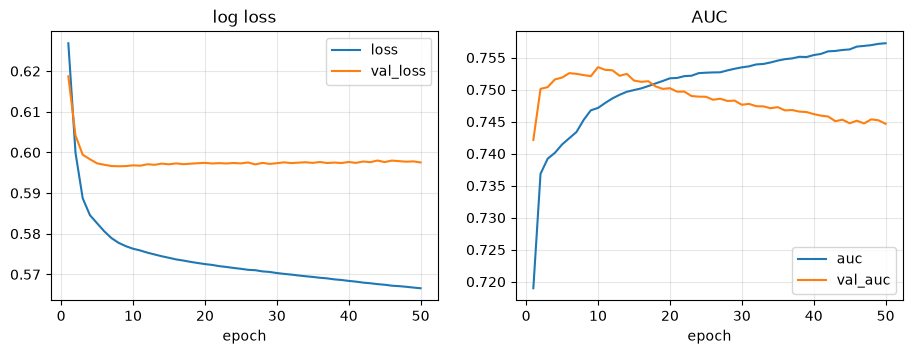

In [7]:
h = pd.DataFrame(history.history)
h.index += 1                                     # epochs start at 1
print(h.loc[[1, 10, 25, 50], ["auc", "val_auc"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
h[["loss", "val_loss"]].plot(ax=axes[0], title="log loss")
h[["auc", "val_auc"]].plot(ax=axes[1], title="AUC")
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=.3)
plt.show()

The validation AUC is high after the very first epoch, peaks around epoch 10, then drifts down while the training AUC keeps rising: the network has learned what this table offers and starts memorising. Lesson 08.6 shows how to stop at the right moment.

## 5. Evaluate on the test customers

In [8]:
from sklearn.metrics import roc_auc_score
loss, acc, auc = model.evaluate(Xs_test, y_test, verbose=0)
print(f"test log loss {loss:.3f}, accuracy {acc:.1%}, AUC {auc:.3f}")
p_net = model.predict(Xs_test, verbose=0).ravel()
p_lr = logreg.predict_proba(Xs_test)[:, 1]
print(f"\n{'model':28s}{'params':>8s}{'test AUC':>10s}")
print(f"{'logistic regression':28s}{6:>8d}{roc_auc_score(y_test, p_lr):>10.3f}")
print(f"{'neural network 5-16-8-1':28s}{model.count_params():>8d}{roc_auc_score(y_test, p_net):>10.3f}")

test log loss 0.581, accuracy 67.3%, AUC 0.740



model                         params  test AUC
logistic regression                6     0.741
neural network 5-16-8-1          241     0.740


A tie, as the README explains: five meaningful columns with mostly straight-line effects leave nothing for hidden layers to discover. (Your last digit may differ slightly; neural network results vary a little between machines.)

## 6. Predict

`predict` returns one churn probability per customer. The two models mostly agree on who is risky:

In [9]:
print("first five customers, network :", p_net[:5].round(3))
print("first five customers, logistic:", p_lr[:5].round(3))
print(f"correlation between the two models' scores: {np.corrcoef(p_net, p_lr)[0, 1]:.3f}")

first five customers, network : [0.699 0.665 0.359 0.449 0.674]
first five customers, logistic: [0.676 0.646 0.36  0.497 0.664]
correlation between the two models' scores: 0.971


## 7. Save and load

Keras saves the architecture, the weights and the compile settings in one `.keras` file. Models go in the repo's `models/` folder, which git ignores.

In [10]:
models_dir = data_path("download.py").parent.parent / "models"
models_dir.mkdir(exist_ok=True)
model.save(models_dir / "churn_network.keras")
reloaded = keras.models.load_model(models_dir / "churn_network.keras")
same = np.allclose(reloaded.predict(Xs_test, verbose=0).ravel(), p_net)
print("reloaded model gives identical predictions:", same)

reloaded model gives identical predictions: True


In production you would save the fitted `scaler` alongside it (with `joblib`, lesson 05.10), because the network only understands scaled inputs.

## Quiz answers

1. Build, compile, fit, evaluate, predict.
2. How to learn: the optimiser (update rule and learning rate), the loss to minimise and the metrics to report.
3. $16 \times 8 + 8 = 136$.
4. An epoch is one pass through every training row. A batch is the group of rows used for one update step.
5. Any of: the table has only five columns, already meaningful and mostly linear in their effect, so there are no hidden features to learn; 2,487 customers are not many for 241 parameters; logistic regression already captures what the data supports.

**Next:** [08.6 Training well](../06-training-well/)